<a href="https://colab.research.google.com/github/Alvacampos/VC---vision_por_computadora/blob/main/parte1_pipeline_vehiculos_blancos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evaluación integradora – Parte 1
## Pipeline de visión por computadora: detección de vehículos blancos en video con registro de eventos

**Materia:** Visión por Computadora (Lic. en Inteligencia Artificial, UBP)
**Base de trabajo:** Actividad 4 del Módulo 1 (*Mini pipeline integrador*) y Actividad 2 del Módulo 2 (*Detección en video con registro de eventos*).

Estructura del notebook (sigue los entregables mínimos del enunciado):

1. Descripción del problema y escenario de aplicación
2. Inspección inicial del material visual
3. Preprocesamiento implementado y justificado
4. Detección de objetos y segmentación básica por color
5. Reglas temporales y registro estructurado de eventos (CSV)
6. Evidencia visual
7. Validación manual, errores y limitaciones
8. Referencias al material de la materia

## 1. Descripción del problema y escenario de aplicación

**Contexto.** El material de la materia ubica a la *movilidad inteligente* y la *analítica de video* entre los casos de uso actuales de la visión por computadora (Módulo 2, pág. 35; Contenidos, pág. 7). En ese escenario, un operador necesita saber **cuándo** aparece en cámara un vehículo con una característica visual concreta (por ejemplo, el color informado en una alerta) sin revisar el video completo a mano.

**Problema formulado en una oración** (como pide la Actividad 4 del Módulo 1, pág. 29):
> *Detectar automáticamente los vehículos de color blanco que aparecen en un video de tránsito y registrar, para cada aparición, el frame y el timestamp (minuto:segundo) de inicio y fin, de modo que el registro pueda revisarse y analizarse después.*

La formulación sigue la indicación del Módulo 2 de pasar del caso de uso al requerimiento técnico: no es lo mismo "detectar autos" que definir qué se detecta, con qué tolerancia y cómo se reporta (pág. 35).

**Tareas de visión involucradas** (Módulo 1, pág. 14): *detección* (localizar y clasificar vehículos con cajas), *segmentación* básica (máscara de píxeles blancos dentro de cada caja) y *seguimiento* simple (mantener la identidad del vehículo entre frames para convertir detecciones en eventos).

**Material visual.** Video real de tránsito filmado con una cámara frontal en una autopista de varios carriles: 1280×720 px, 25 FPS, 1260 frames (50,4 s), de día y con cambios de pavimento (asfalto oscuro y hormigón claro), sombras y vehículos que se tapan entre sí. Fuente pública: `project_video.mp4` del repositorio *udacity/CarND-Vehicle-Detection* (licencia MIT).

**Alcance y supuestos.**

| Aspecto | Definición adoptada |
|---|---|
| Objeto de interés | Vehículos de las clases `car`, `bus` y `motorbike` del detector preentrenado |
| "Vehículo blanco" | Vehículo cuya carrocería (zona central de la caja) tiene al menos **30 %** de píxeles con saturación baja (S ≤ 40) y brillo alto (V ≥ 170) en HSV |
| Evento | Una **aparición**: el mismo vehículo detectado al menos **3 frames consecutivos** (regla sugerida en la Actividad 2 del Módulo 2, pág. 46) |
| Fin del evento | El vehículo deja de detectarse durante más de 12 frames (≈0,5 s) |
| Salida | `eventos.csv` (una fila por aparición) y `detecciones.csv` (una fila por detección y frame) |
| Fuera de alcance | Vehículos muy lejanos (caja menor a 12 px), reidentificación entre oclusiones largas y otros colores |

## 2. Inspección inicial del material visual

Antes de transformar los datos se inspecciona su estructura: dimensiones, tipo de dato, rango de valores y orden de canales. El Módulo 1 lo plantea como "una de las primeras buenas prácticas" (pág. 16) y la Actividad 1 detalla qué revisar (`.shape`, `.dtype`, `.min()`, `.max()`, conversión BGR→RGB para mostrar con `matplotlib`, pág. 23).

In [1]:
!pip install -q opencv-python-headless==4.10.0.84 opencv-python==4.10.0.84

In [2]:
import os, json, time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("OpenCV", cv2.__version__, "| NumPy", np.__version__, "| pandas", pd.__version__)

RUTA_VIDEO   = "data/video_transito.mp4"
RUTA_PROTO   = "modelos/deploy.prototxt"
RUTA_PESOS   = "modelos/mobilenet_iter_73000.caffemodel"
DIR_RES      = "resultados"
os.makedirs(f"{DIR_RES}/evidencias", exist_ok=True)

def mostrar(imgs, titulos, figsize=(16, 4), cmap=None):
    # Muestra imágenes BGR (o máscaras) lado a lado, convirtiendo BGR->RGB para matplotlib
    fig, axs = plt.subplots(1, len(imgs), figsize=figsize)
    axs = np.atleast_1d(axs)
    for ax, im, t in zip(axs, imgs, titulos):
        if im.ndim == 3:
            ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(im, cmap=cmap or "gray")
        ax.set_title(t, fontsize=10); ax.axis("off")
    plt.tight_layout(); plt.show()

OpenCV 4.10.0 | NumPy 2.4.6 | pandas 2.2.3


,fps,frames,duración (s),shape frame,dtype,min,max
0,25.0,1260,50.4,"(720, 1280, 3)",uint8,0,255


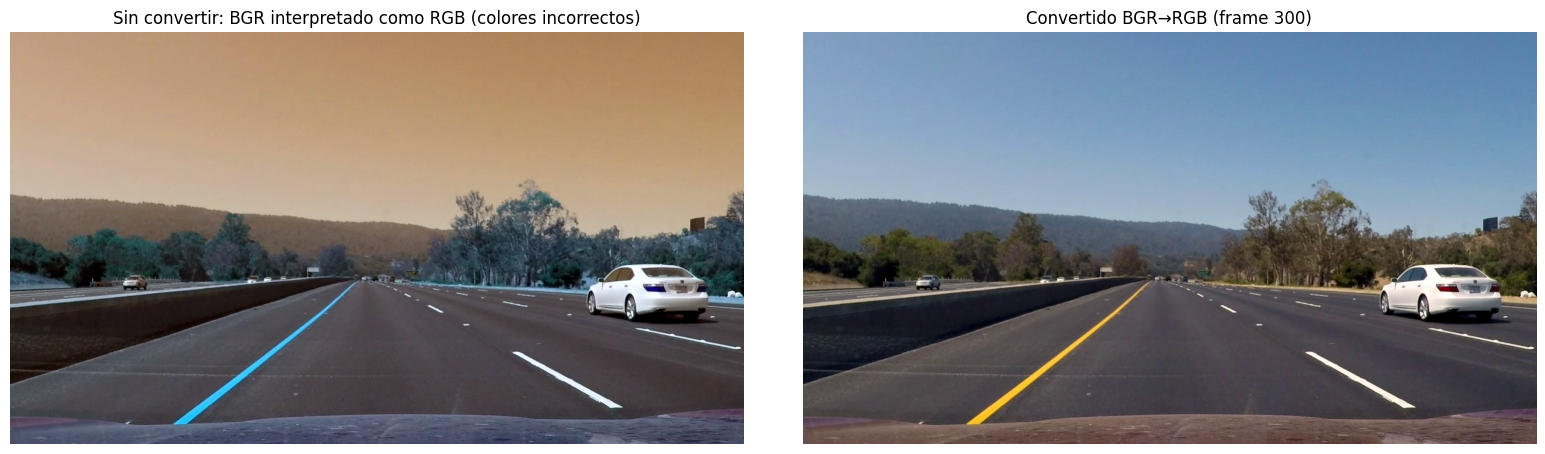

In [3]:
cap = cv2.VideoCapture(RUTA_VIDEO)
assert cap.isOpened(), "No se pudo abrir el video: revisar ruta, formato y códec"
FPS      = cap.get(cv2.CAP_PROP_FPS)
N_FRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
ANCHO    = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
ALTO     = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.set(cv2.CAP_PROP_POS_FRAMES, 300)
ok, frame_ej = cap.read()
cap.release()

inspeccion = pd.DataFrame([{
    "fps": FPS, "frames": N_FRAMES, "duración (s)": round(N_FRAMES / FPS, 2),
    "shape frame": frame_ej.shape, "dtype": str(frame_ej.dtype),
    "min": int(frame_ej.min()), "max": int(frame_ej.max()),
}])
display(inspeccion)

rgb_mal = frame_ej                    # mostrado "tal cual" (BGR interpretado como RGB)
fig, axs = plt.subplots(1, 2, figsize=(16, 4.5))
axs[0].imshow(rgb_mal); axs[0].set_title("Sin convertir: BGR interpretado como RGB (colores incorrectos)")
axs[1].imshow(cv2.cvtColor(frame_ej, cv2.COLOR_BGR2RGB)); axs[1].set_title("Convertido BGR→RGB (frame 300)")
for a in axs: a.axis("off")
plt.tight_layout(); plt.show()

**Lectura de la inspección.** Cada frame es una matriz `uint8` de 720×1280×3 (casi 2,8 millones de valores por frame) con valores en 0–255. OpenCV entrega los canales en orden **BGR** (Módulo 1, pág. 18 y glosario pág. 21): si no se convierte, los colores se ven alterados, que es exactamente el error que la Actividad 1 pide evitar. Para un problema de *color* este detalle es crítico, porque una conversión equivocada cambia el criterio de "blanco".

Además, la parte superior del frame es cielo y la inferior es el capot del vehículo que filma: ninguna de las dos aporta información sobre vehículos. Eso motiva el recorte de región de interés del paso siguiente.

## 3. Preprocesamiento implementado y justificado

El Módulo 1 insiste en que "preprocesar no es aplicar filtros porque sí: cada transformación debe tener un objetivo técnico que pueda justificarse" (pág. 17). La tabla resume cada etapa, su objetivo y el apartado del material que la respalda.

| # | Operación | Parámetros | Objetivo técnico | Respaldo en el material |
|---|---|---|---|---|
| P1 | **Recorte de región de interés (ROI)** | filas 380–680 | Quitar cielo y capot: menos falsos positivos y menos cómputo | Act. 3 y 5 del Mód. 1: "si el fondo genera muchos falsos positivos, pruebe recortar una región de interés" (págs. 27 y 31) |
| P2 | **Partición en 3 recortes solapados** | 3 × 560 px de ancho, solape 200 px | La franja es 1280×300; llevarla entera a 300×300 aplasta los autos lejanos (factor 4,3 en horizontal). Con recortes de 560 px el factor baja a 1,9 | Redimensionado para "estandarizar tamaños de entrada" (Mód. 1, pág. 17); "si las cajas están mal ubicadas, observe si hay escala muy pequeña" (Act. 1, Mód. 2, pág. 45) |
| P3 | **Redimensionado + normalización** del recorte para la red | 300×300, `(x − 127,5) · 0,007843` → rango [−1, 1] | Entrada que espera el modelo preentrenado | Normalización a rango decimal (Mód. 1, pág. 16) |
| P4 | **Suavizado gaussiano** del recorte de cada vehículo | kernel 5×5 | Atenuar reflejos y ruido de compresión antes de umbralizar color | "Un suavizado puede reducir pequeñas variaciones producidas por ruido" (Mód. 1, pág. 17) |
| P5 | **Conversión BGR → HSV** | `cv2.COLOR_BGR2HSV` | Separar el color (H, S) del brillo (V): el blanco se define por S baja y V alta, más estable ante cambios de luz que un umbral en RGB | "En HSV… esto puede facilitar ciertos problemas de detección por color" (Mód. 1, pág. 18) |
| P6 | **Recorte central de la caja** | se descarta 15 % por borde | Evitar que asfalto, sombra o líneas pintadas dentro de la caja se cuenten como carrocería | La caja "puede incluir fondo o elementos irrelevantes" (Mód. 2, pág. 37) |
| P7 | **Apertura morfológica** de la máscara | elipse 3×3 | Eliminar píxeles blancos aislados (brillos puntuales) | "Operaciones morfológicas para limpiar máscaras" (Mód. 2, pág. 37) |

In [4]:
PARAMS = dict(
    roi_y=(380, 680),                                  # P1
    tiles=((0, 560), (360, 920), (720, 1280)),         # P2
    blob_escala=0.007843, blob_media=127.5,            # P3
    blur_k=5,                                          # P4
    hsv_s_max=40, hsv_v_min=170,                       # P5 (criterio de "blanco")
    margen_caja=0.15,                                  # P6
    morf_k=3,                                          # P7
    conf_umbral=0.75,           # detector (elegido en la sección 5 tras comparar 0.25 / 0.50 / 0.75)
    nms_iou=0.40,               # NMS entre recortes
    contencion_max=0.60,        # caja contenida en otra mayor -> redundante
    ancho_max_rel=0.80,         # descarta cajas que ocupan casi todo un recorte (ver sección 4)
    lado_min=12,                # px
    ratio_blanco_min=0.30,      # fracción de píxeles blancos para clasificar "auto blanco"
    iou_asociacion=0.25,        # seguimiento
    persistencia_min=3,         # frames consecutivos para confirmar un evento
    max_frames_perdido=12,      # ≈0,5 s sin detección cierra el evento
    ventana_fusion_s=4.0,       # ventana mínima entre eventos del mismo vehículo/color (ajustada en 5.1)
)
json.dump(PARAMS, open(f"{DIR_RES}/parametros.json", "w"), indent=2)   # trazabilidad
PARAMS

{'roi_y': (380, 680),
 'tiles': ((0, 560), (360, 920), (720, 1280)),
 'blob_escala': 0.007843,
 'blob_media': 127.5,
 'blur_k': 5,
 'hsv_s_max': 40,
 'hsv_v_min': 170,
 'margen_caja': 0.15,
 'morf_k': 3,
 'conf_umbral': 0.75,
 'nms_iou': 0.4,
 'contencion_max': 0.6,
 'ancho_max_rel': 0.8,
 'lado_min': 12,
 'ratio_blanco_min': 0.3,
 'iou_asociacion': 0.25,
 'persistencia_min': 3,
 'max_frames_perdido': 12,
 'ventana_fusion_s': 4.0}

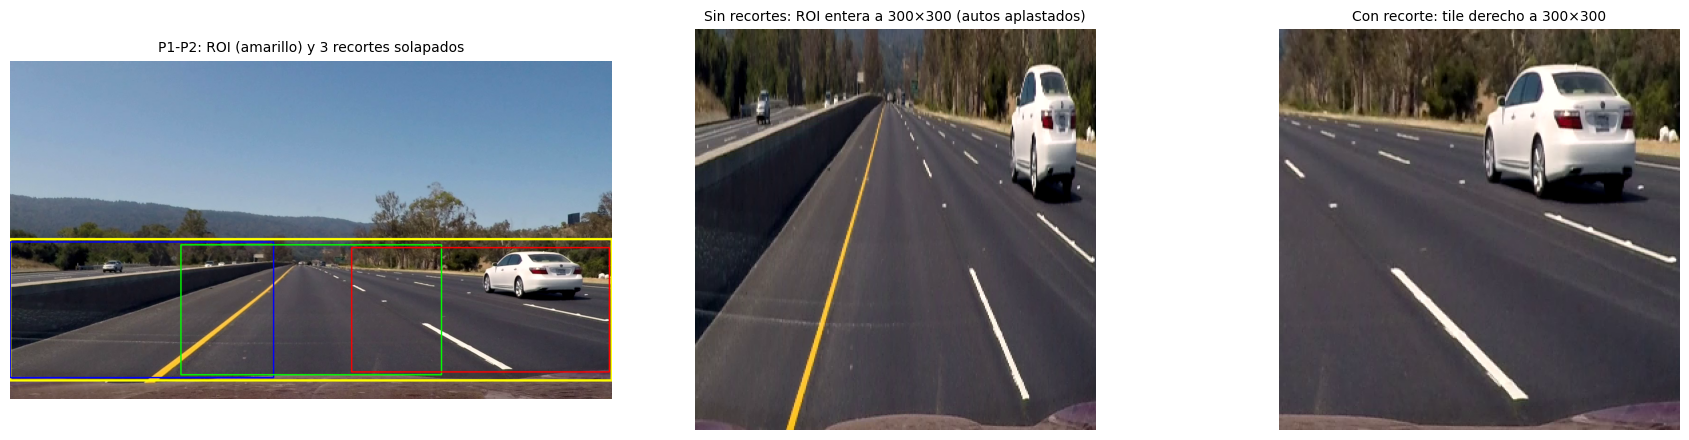

In [5]:
# Salidas intermedias del preprocesamiento sobre el frame de ejemplo
y0, y1 = PARAMS["roi_y"]
vis = frame_ej.copy()
cv2.rectangle(vis, (0, y0), (ANCHO - 1, y1), (0, 255, 255), 3)
for i, (x0, x1) in enumerate(PARAMS["tiles"]):
    col = [(255, 0, 0), (0, 255, 0), (0, 0, 255)][i]
    cv2.rectangle(vis, (x0 + 3 * i, y0 + 6 + 6 * i), (x1 - 3 * i, y1 - 6 - 6 * i), col, 2)
roi = frame_ej[y0:y1]
aplastada = cv2.resize(roi, (300, 300))
tile_med = cv2.resize(roi[:, 720:1280], (300, 300))
mostrar([vis, aplastada, tile_med],
        ["P1-P2: ROI (amarillo) y 3 recortes solapados", "Sin recortes: ROI entera a 300×300 (autos aplastados)",
         "Con recorte: tile derecho a 300×300"], figsize=(18, 4.5))

### 3.1 Comparación de dos pipelines de color (en el formato de la Actividad 2 del Módulo 1)

Para justificar P4–P7 se comparan dos secuencias sobre los mismos vehículos (pág. 25):

* **Pipeline A (ingenuo):** caja completa, sin suavizado, umbral en RGB (los tres canales ≥ 170).
* **Pipeline B (elegido):** recorte central + suavizado gaussiano + HSV (S ≤ 40, V ≥ 170) + apertura morfológica.

Se aplica a un auto **blanco** y a uno **negro** (con reflejos del sol). Lo que interesa no es una imagen "más linda", sino que la proporción de píxeles blancos **separe** claramente las dos clases.

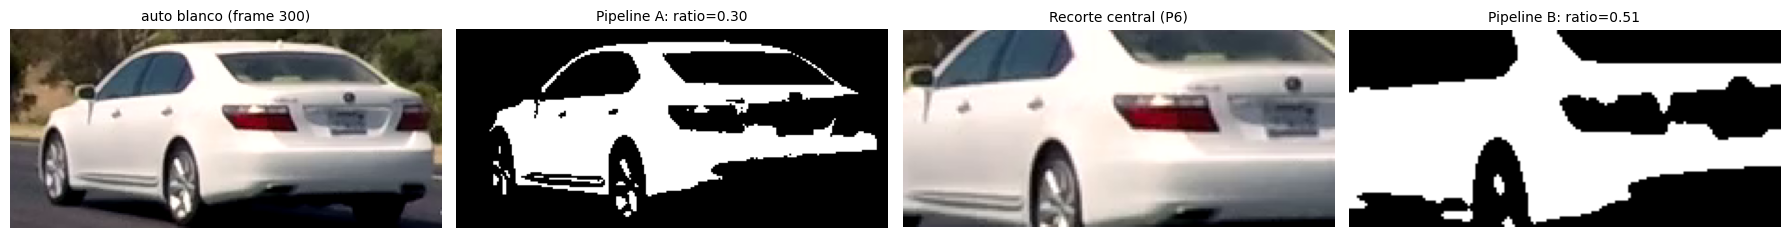

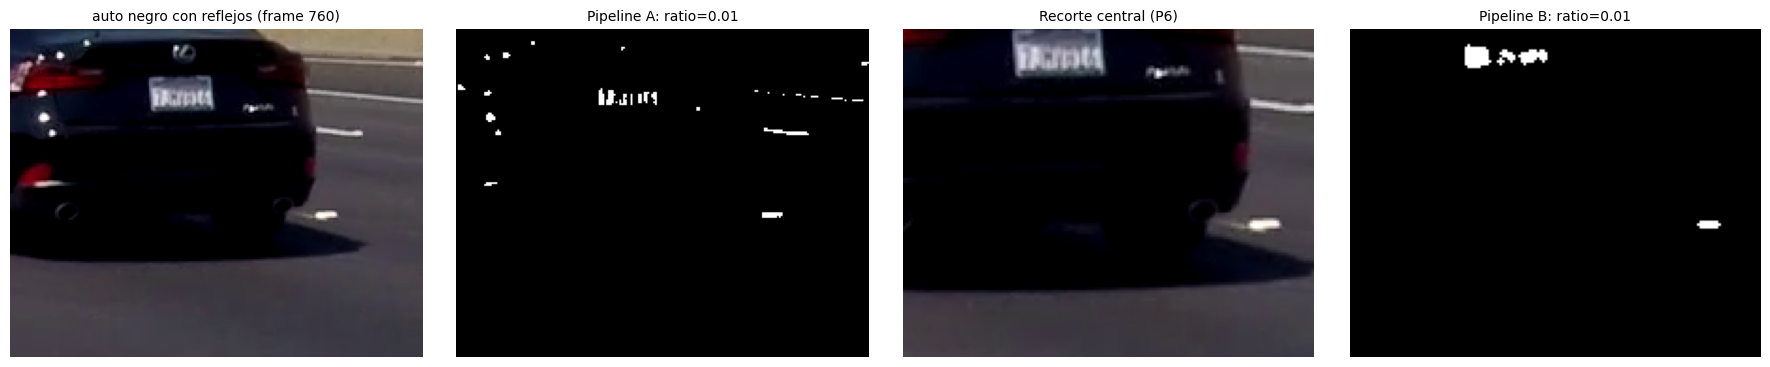

,caso,"ratio A (RGB, caja completa)",ratio B (HSV + blur + morf.)
0,auto blanco (frame 300),0.304,0.513
1,auto negro con reflejos (frame 760),0.008,0.008


In [6]:
def mascara_A(recorte):
    return cv2.inRange(recorte, (170, 170, 170), (255, 255, 255))

def mascara_B(recorte, p=PARAMS):
    suav = cv2.GaussianBlur(recorte, (p["blur_k"], p["blur_k"]), 0)                 # P4
    hsv = cv2.cvtColor(suav, cv2.COLOR_BGR2HSV)                                      # P5
    m = cv2.inRange(hsv, (0, 0, p["hsv_v_min"]), (180, p["hsv_s_max"], 255))
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (p["morf_k"], p["morf_k"]))
    return cv2.morphologyEx(m, cv2.MORPH_OPEN, k)                                     # P7

def recorte_central(frame, caja, margen=PARAMS["margen_caja"]):                       # P6
    x1, y1, x2, y2 = caja[:4]
    dx, dy = int((x2 - x1) * margen), int((y2 - y1) * margen)
    return frame[y1 + dy:y2 - dy, x1 + dx:x2 - dx]

def ratio(m):
    return float(np.count_nonzero(m)) / m.size if m.size else 0.0

def leer_frame(n):
    c = cv2.VideoCapture(RUTA_VIDEO); c.set(cv2.CAP_PROP_POS_FRAMES, n); ok, f = c.read(); c.release(); return f

# Cajas de referencia marcadas a mano (frame, x1, y1, x2, y2) para la comparación
casos = {"auto blanco (frame 300)": (300, 990, 400, 1222, 507),
         "auto negro con reflejos (frame 760)": (760, 1060, 440, 1280, 615)}
filas = []
for nombre, (nf, *caja) in casos.items():
    f = leer_frame(nf)
    completo = f[caja[1]:caja[3], caja[0]:caja[2]]
    central = recorte_central(f, caja)
    mA, mB = mascara_A(completo), mascara_B(central)
    mostrar([completo, mA, central, mB],
            [f"{nombre}", f"Pipeline A: ratio={ratio(mA):.2f}", "Recorte central (P6)", f"Pipeline B: ratio={ratio(mB):.2f}"],
            figsize=(18, 3.6))
    filas.append({"caso": nombre, "ratio A (RGB, caja completa)": round(ratio(mA), 3),
                  "ratio B (HSV + blur + morf.)": round(ratio(mB), 3)})
display(pd.DataFrame(filas))

La tabla final de esta sección (3.2) cuantifica la separación sobre **todas** las detecciones del video, una vez ejecutado el detector.

## 4. Detección de objetos y segmentación básica

**Detector.** Se usa un modelo **preentrenado** de detección (MobileNet-SSD, 20 clases del dataset PASCAL VOC, entre ellas `car`, `bus` y `motorbike`) ejecutado con el módulo **DNN de OpenCV**, como sugiere la lectura complementaria del Módulo 2 ("ejemplos de inferencia disponibles en OpenCV DNN para trabajar con modelos preentrenados", pág. 36). Los modelos preentrenados "permiten construir rápidamente una línea base de trabajo" (pág. 36).

Conceptos aplicados (Módulo 2, pág. 36): *bounding box*, *score de confianza*, *umbral de detección* y *NMS* para eliminar cajas redundantes (aquí, también las que aparecen duplicadas en la zona de solape entre recortes).

**Filtro adicional observado en las pruebas.** Con fondos uniformes (muro de hormigón y pavimento) el detector a veces devuelve una caja `car` que cubre **todo** el recorte izquierdo. Siguiendo la recomendación "si detecta demasiados falsos positivos, agregue restricciones de tamaño" (Act. 5, Mód. 1, pág. 31), se descartan cajas con ancho mayor al 80 % del recorte.

**Segmentación.** Dentro de cada caja se calcula la máscara de píxeles blancos (pipeline B). La caja dice *dónde* está el vehículo; la máscara dice *qué parte* de él es carrocería blanca, que es justamente el caso en que conviene segmentar porque la caja "no puede representar de manera suficiente" el área de interés (Módulo 2, pág. 37).

In [7]:
CLASES = ["background", "aeroplane", "bicycle", "bird", "boat", "bottle", "bus", "car", "cat", "chair", "cow",
          "diningtable", "dog", "horse", "motorbike", "person", "pottedplant", "sheep", "sofa", "train", "tvmonitor"]
CLASES_VEHICULO = {"car", "bus", "motorbike"}
net = cv2.dnn.readNetFromCaffe(RUTA_PROTO, RUTA_PESOS)

CONF_MIN_GUARDADO = 0.25   # se guarda todo desde 0.25 para poder comparar umbrales sin re-ejecutar la red

def detectar_vehiculos(frame, p=PARAMS, conf_min=CONF_MIN_GUARDADO):
    y0, y1 = p["roi_y"]
    roi = frame[y0:y1]                                                         # P1
    cajas, confs, clases = [], [], []
    for (x0, x1) in p["tiles"]:                                                # P2
        tile = roi[:, x0:x1]
        h, w = tile.shape[:2]
        blob = cv2.dnn.blobFromImage(cv2.resize(tile, (300, 300)), p["blob_escala"], (300, 300), p["blob_media"])  # P3
        net.setInput(blob)
        det = net.forward()
        for k in range(det.shape[2]):
            conf, nombre = float(det[0, 0, k, 2]), CLASES[int(det[0, 0, k, 1])]
            if conf < conf_min or nombre not in CLASES_VEHICULO:
                continue
            bx1, by1, bx2, by2 = det[0, 0, k, 3:7] * [w, h, w, h]
            bx1, bx2 = np.clip([bx1, bx2], 0, w - 1)
            by1, by2 = np.clip([by1, by2], 0, h - 1)
            if (bx2 - bx1) > p["ancho_max_rel"] * w:                             # filtro de tamaño
                continue
            if bx2 - bx1 < p["lado_min"] or by2 - by1 < p["lado_min"]:
                continue
            cajas.append([int(bx1 + x0), int(by1 + y0), int(bx2 - bx1), int(by2 - by1)])
            confs.append(conf); clases.append(nombre)
    salida = []
    if cajas:
        for i in np.array(cv2.dnn.NMSBoxes(cajas, confs, conf_min, p["nms_iou"])).flatten():   # NMS
            x, y, w, h = cajas[i]
            salida.append((x, y, x + w, y + h, confs[i], clases[i]))
    # Cajas contenidas: NMS compara por IoU, pero una caja parcial dentro de otra mayor (p. ej. media carrocería)
    # puede tener IoU bajo. Si más del 60 % de una caja cae dentro de otra mayor, se considera redundante.
    def contenida(a, b):
        ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
        area_a = (a[2] - a[0]) * (a[3] - a[1])
        return area_a <= (b[2] - b[0]) * (b[3] - b[1]) and ix * iy / area_a > p["contencion_max"]
    return [a for a in salida if not any(a is not b and contenida(a, b) for b in salida)]

### 4.1 Procesamiento frame a frame

Se procesan **todos** los frames (la Actividad 2 del Módulo 2 permite procesar uno cada *n*, pág. 45; con 1260 frames el costo es aceptable y se gana resolución temporal). Para cada detección se guarda número de frame, timestamp, clase, confianza, caja y proporción de píxeles blancos. Ese registro crudo (`detecciones.csv`) permite auditar cualquier evento posterior.

In [8]:
def seg_a_mmss(s):
    m, r = divmod(s, 60)
    return f"{int(m):02d}:{r:05.2f}"

cap = cv2.VideoCapture(RUTA_VIDEO)
filas, n, t0 = [], 0, time.time()
while True:
    ok, frame = cap.read()
    if not ok:
        break
    for (x1, y1, x2, y2, conf, clase) in detectar_vehiculos(frame):
        cen = recorte_central(frame, (x1, y1, x2, y2))
        filas.append(dict(frame=n, t_s=round(n / FPS, 3), timestamp=seg_a_mmss(n / FPS), minuto=int(n / FPS // 60),
                          clase=clase, conf=round(conf, 3), x1=x1, y1=y1, x2=x2, y2=y2,
                          ratio_blanco=round(ratio(mascara_B(cen)), 3),
                          ratio_blanco_A=round(ratio(mascara_A(frame[y1:y2, x1:x2])), 3)))
    n += 1
cap.release()
dt = time.time() - t0
det_todas = pd.DataFrame(filas)
print(f"{n} frames procesados en {dt:.1f} s ({n/dt:.1f} FPS de procesamiento, video a {FPS:.0f} FPS)")
print(f"Detecciones con conf ≥ {CONF_MIN_GUARDADO}: {len(det_todas)}")
det_todas.head()

1260 frames procesados en 286.2 s (4.4 FPS de procesamiento, video a 25 FPS)
Detecciones con conf ≥ 0.25: 1695


,frame,t_s,timestamp,minuto,clase,conf,x1,y1,x2,y2,ratio_blanco,ratio_blanco_A
0,112,4.48,00:04.48,0,car,0.258,118,417,163,446,0.231,0.171
1,113,4.52,00:04.52,0,car,0.324,104,417,153,448,0.188,0.142
2,130,5.20,00:05.20,0,car,0.301,1205,433,1274,532,0.462,0.353
3,131,5.24,00:05.24,0,car,0.749,1204,433,1278,532,0.512,0.377
4,132,5.28,00:05.28,0,car,0.768,1198,430,1278,530,0.530,0.371


### 4.2 Comparación de umbrales de confianza

La Actividad 1 del Módulo 2 pide repetir la inferencia con al menos tres umbrales (0,25 / 0,50 / 0,75) y analizar la tensión entre falsos positivos y falsos negativos (págs. 36 y 43). Como las detecciones se guardaron desde 0,25, se filtran sin volver a ejecutar la red. El conteo de eventos de cada umbral se completa en la sección 5.

,umbral,detecciones,frames con ≥1 vehículo,detecciones por frame (media)
0,0.25,1695,1132,1.35
1,0.50,1585,1129,1.26
2,0.75,1514,1111,1.20


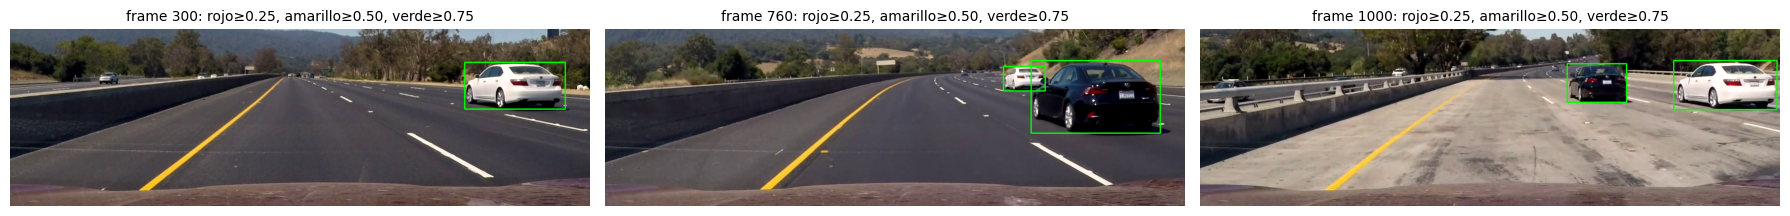

In [9]:
resumen_umbral = []
for u in (0.25, 0.50, 0.75):
    d = det_todas[det_todas.conf >= u]
    resumen_umbral.append({"umbral": u, "detecciones": len(d), "frames con ≥1 vehículo": d.frame.nunique(),
                           "detecciones por frame (media)": round(len(d) / N_FRAMES, 2)})
display(pd.DataFrame(resumen_umbral))

frames_demo = [300, 760, 1000]
imgs = []
for nf in frames_demo:
    f = leer_frame(nf)
    for u, col in ((0.25, (0, 0, 255)), (0.50, (0, 255, 255)), (0.75, (0, 255, 0))):
        for _, r in det_todas[(det_todas.frame == nf) & (det_todas.conf >= u)].iterrows():
            cv2.rectangle(f, (r.x1, r.y1), (r.x2, r.y2), col, 2)
    imgs.append(f[330:720])
mostrar(imgs, [f"frame {k}: rojo≥0.25, amarillo≥0.50, verde≥0.75" for k in frames_demo], figsize=(18, 3.8))

### 4.3 Separación entre clases de color (justificación cuantitativa de P4–P7)

Se compara la proporción de píxeles blancos que asigna cada pipeline a las detecciones (con el umbral de confianza adoptado) de los tres vehículos cercanos que aparecen en el video. Las etiquetas *blanco/negro* de esta tabla salen de la revisión manual de la sección 7, por posición de la caja.

,A p5,A mediana,A p95,B p5,B mediana,B p95,n detecciones
etiqueta_manual,,,,,,,
blanco,0.255,0.344,0.433,0.415,0.532,0.629,941.0
negro,0.010,0.015,0.046,0.010,0.017,0.023,560.0


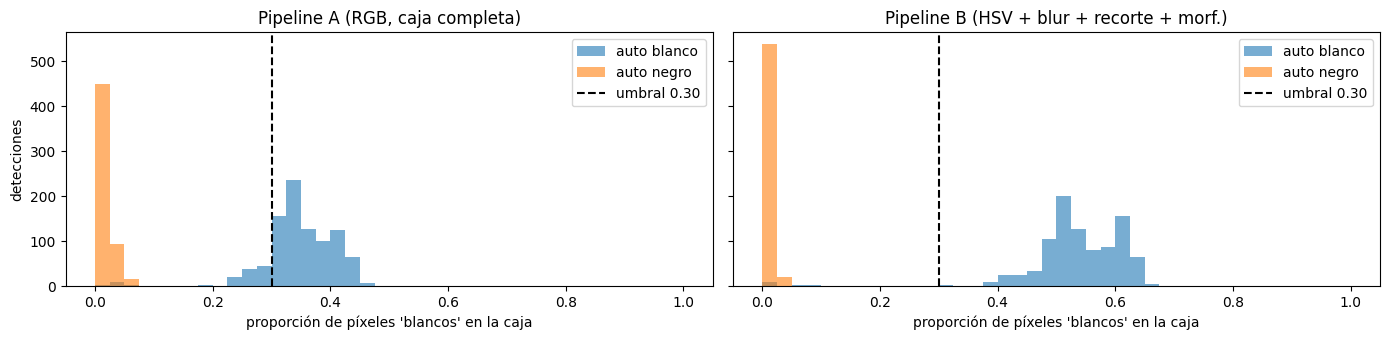

Pipeline A: detecciones del auto blanco bajo el umbral 0.30 = 12.9% | detecciones del auto negro sobre el umbral = 0.0%
Pipeline B: detecciones del auto blanco bajo el umbral 0.30 = 1.8% | detecciones del auto negro sobre el umbral = 0.0%


In [10]:
# Etiquetas manuales por rango de frames y posición, obtenidas al revisar el video cuadro a cuadro (sección 7):
#  - Auto blanco: visible del frame ~125 al ~1210 (pasa detrás del negro entre ~810 y ~870).
#  - Auto negro 1: entra por la derecha en el frame ~690 y queda delante hasta el final.
#  - Auto negro 2: entra por la derecha en el frame ~1243.
# Para no depender del color (que es lo que se quiere medir), la etiqueta se asigna por GEOMETRÍA:
# hasta el frame 687 el único vehículo cercano es el blanco; después, el negro 1 es la caja que está
# a la izquierda del blanco (salvo entre 688 y 800, cuando el negro va adelante a la derecha y es la caja más grande).
def etiqueta_geometrica(r):
    alto = r.y2 - r.y1
    if alto < 40:
        return None                       # vehículos lejanos: no se etiquetan
    if r.frame < 688:
        return "blanco"
    if r.frame < 800:
        return "negro" if alto >= 90 else "blanco"   # el negro está cerca (caja alta), el blanco lejos
    if r.frame >= 1243 and r.x1 >= 1150 and r.x2 >= 1270 and r.y2 > 470 and alto >= 60:
        return None                       # entrada del negro 2 en el borde: ambigua con el blanco saliente
    return "blanco" if (r.x1 + r.x2) / 2 > 1000 else "negro"

d50 = det_todas[det_todas.conf >= PARAMS["conf_umbral"]].copy()
d50["etiqueta_manual"] = d50.apply(etiqueta_geometrica, axis=1)
d50 = d50.dropna(subset=["etiqueta_manual"])
sep = d50.groupby("etiqueta_manual")[["ratio_blanco_A", "ratio_blanco"]].describe(percentiles=[.05, .5, .95])
cols = [("ratio_blanco_A", "5%"), ("ratio_blanco_A", "50%"), ("ratio_blanco_A", "95%"),
        ("ratio_blanco", "5%"), ("ratio_blanco", "50%"), ("ratio_blanco", "95%"), ("ratio_blanco", "count")]
tabla_sep = sep[cols].round(3)
tabla_sep.columns = ["A p5", "A mediana", "A p95", "B p5", "B mediana", "B p95", "n detecciones"]
display(tabla_sep)

fig, axs = plt.subplots(1, 2, figsize=(14, 3.5), sharey=True)
for ax, col, tit in ((axs[0], "ratio_blanco_A", "Pipeline A (RGB, caja completa)"),
                     (axs[1], "ratio_blanco", "Pipeline B (HSV + blur + recorte + morf.)")):
    for et, c in (("blanco", "tab:blue"), ("negro", "tab:orange")):
        ax.hist(d50[d50.etiqueta_manual == et][col], bins=40, range=(0, 1), alpha=.6, label=f"auto {et}", color=c)
    ax.axvline(PARAMS["ratio_blanco_min"], color="k", ls="--", label="umbral 0.30")
    ax.set_title(tit); ax.set_xlabel("proporción de píxeles 'blancos' en la caja"); ax.legend()
axs[0].set_ylabel("detecciones")
plt.tight_layout(); plt.savefig(f"{DIR_RES}/evidencias/separacion_pipelines.png", dpi=110); plt.show()
for col, nom in (("ratio_blanco_A", "A"), ("ratio_blanco", "B")):
    bl = d50[d50.etiqueta_manual == "blanco"][col]; ng = d50[d50.etiqueta_manual == "negro"][col]
    print(f"Pipeline {nom}: detecciones del auto blanco bajo el umbral 0.30 = {(bl < 0.30).mean():.1%} | "
          f"detecciones del auto negro sobre el umbral = {(ng >= 0.30).mean():.1%}")

## 5. Reglas temporales y registro estructurado de eventos

El Módulo 2 advierte que en video hay que "no confundir una detección aislada con un evento útil" y que suele ser preferible obtener "menos detecciones, pero más estables" (págs. 36–37). Por eso las detecciones se convierten en eventos con tres reglas, todas tomadas de la Actividad 2 del Módulo 2 (págs. 45–47):

1. **Seguimiento simple por IoU.** Cada detección se asocia con el vehículo del frame anterior con el que más se superpone (IoU ≥ 0,25; IoU según el glosario del Mód. 2, pág. 42). Si no hay coincidencia, se abre un nuevo *track*.
2. **Persistencia temporal.** Un track recién se confirma como evento cuando se detecta en **3 frames consecutivos** ("si la detección aparece durante 3 frames consecutivos", pág. 45; "si se registran eventos inestables, agregue una regla de persistencia temporal", pág. 47).
3. **Cierre y ventana mínima entre eventos.** El evento termina si el vehículo no se detecta durante más de 12 frames. Si un vehículo del mismo color vuelve a aparecer en la misma zona dentro de **4 s**, se fusiona con el evento anterior para no contarlo dos veces ("si se cuenta varias veces el mismo objeto, defina una ventana temporal mínima entre eventos", pág. 47). El valor de 4 s surge del ajuste documentado en la sección 5.1.

El color del evento se decide con la **mediana** de la proporción de blanco a lo largo de todos sus frames, que es más robusta que un frame aislado frente a reflejos o sombras momentáneas.

In [11]:
def iou(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0

def generar_eventos(det, umbral, p=PARAMS):
    det = det[det.conf >= umbral]
    por_frame = {k: g for k, g in det.groupby("frame")}
    tracks, cerrados, sig = [], [], 1
    for nf in range(N_FRAMES):
        dets = [] if nf not in por_frame else [
            dict(caja=(r.x1, r.y1, r.x2, r.y2), conf=r.conf, ratio=r.ratio_blanco) for r in por_frame[nf].itertuples()]
        usados = set()
        for t in tracks:                                             # 1) asociación por IoU
            cand = [(iou(t["caja"], d["caja"]), j) for j, d in enumerate(dets) if j not in usados]
            v, j = max(cand, default=(0, -1))
            if j >= 0 and v >= p["iou_asociacion"]:
                d = dets[j]; usados.add(j)
                t.update(caja=d["caja"], ultimo=nf, perdidos=0); t["consec"] += 1; t["hits"] += 1
                t["confs"].append(d["conf"]); t["ratios"].append(d["ratio"]); t["cajas"].append((nf, d["caja"]))
            else:
                t["perdidos"] += 1; t["consec"] = 0
        for j, d in enumerate(dets):
            if j not in usados:
                tracks.append(dict(id=sig, caja=d["caja"], inicio=nf, ultimo=nf, perdidos=0, consec=1, hits=1,
                                   confs=[d["conf"]], ratios=[d["ratio"]], cajas=[(nf, d["caja"])], confirmado=False))
                sig += 1
        for t in tracks:                                             # 2) persistencia
            if t["consec"] >= p["persistencia_min"]:
                t["confirmado"] = True
        vivos = []
        for t in tracks:                                             # 3) cierre
            (cerrados if t["perdidos"] > p["max_frames_perdido"] else vivos).append(t)
        tracks = vivos
    cerrados += tracks
    ev = []
    for t in cerrados:
        if not t["confirmado"]:
            continue
        rmed = float(np.median(t["ratios"]))
        # frame de evidencia: aquel en que el vehículo se ve más grande (caja de mayor área)
        k = int(np.argmax([(c[2] - c[0]) * (c[3] - c[1]) for _, c in t["cajas"]]))
        ev.append(dict(track_ids=str(t["id"]), color="blanco" if rmed >= p["ratio_blanco_min"] else "otro",
                       frame_inicio=t["inicio"], frame_fin=t["ultimo"], frames_detectado=t["hits"],
                       conf_media=float(np.mean(t["confs"])), ratio_blanco_mediana=rmed,
                       frame_evidencia=t["cajas"][k][0], caja_evidencia=t["cajas"][k][1],
                       caja_ini=t["cajas"][0][1], caja_fin=t["cajas"][-1][1]))
    ev.sort(key=lambda e: e["frame_inicio"])
    # 3b) fusión: mismo color, reaparece dentro de la ventana y cerca de donde se perdió
    fusion = []
    for e in ev:
        previo = None
        for f in reversed(fusion):
            gap = (e["frame_inicio"] - f["frame_fin"]) / FPS
            cx_f = (f["caja_fin"][0] + f["caja_fin"][2]) / 2
            cx_e = (e["caja_ini"][0] + e["caja_ini"][2]) / 2
            if f["color"] == e["color"] and -0.5 <= gap <= p["ventana_fusion_s"] and abs(cx_f - cx_e) < 0.25 * ANCHO:
                previo = f; break
        if previo is None:
            fusion.append(dict(e))
        else:
            n1, n2 = previo["frames_detectado"], e["frames_detectado"]
            previo["conf_media"] = (previo["conf_media"] * n1 + e["conf_media"] * n2) / (n1 + n2)
            previo["ratio_blanco_mediana"] = (previo["ratio_blanco_mediana"] * n1 + e["ratio_blanco_mediana"] * n2) / (n1 + n2)
            previo["frames_detectado"] = n1 + n2
            previo["track_ids"] += "+" + e["track_ids"]
            previo["frame_fin"] = max(previo["frame_fin"], e["frame_fin"])
            previo["caja_fin"] = e["caja_fin"]
            area = lambda c: (c[2] - c[0]) * (c[3] - c[1])
            if area(e["caja_evidencia"]) > area(previo["caja_evidencia"]):
                previo["frame_evidencia"], previo["caja_evidencia"] = e["frame_evidencia"], e["caja_evidencia"]
    filas = []
    for i, e in enumerate(fusion, 1):
        filas.append(dict(
            evento_id=i, evento="aparicion_vehiculo_blanco" if e["color"] == "blanco" else "aparicion_vehiculo_otro_color",
            color=e["color"], frame_inicio=e["frame_inicio"], frame_fin=e["frame_fin"],
            timestamp_inicio=seg_a_mmss(e["frame_inicio"] / FPS), timestamp_fin=seg_a_mmss(e["frame_fin"] / FPS),
            minuto=int(e["frame_inicio"] / FPS // 60),
            duracion_s=round((e["frame_fin"] - e["frame_inicio"] + 1) / FPS, 2),
            frames_detectado=e["frames_detectado"], conf_media=round(e["conf_media"], 3),
            ratio_blanco=round(e["ratio_blanco_mediana"], 3), track_ids=e["track_ids"],
            frame_evidencia=e["frame_evidencia"], caja_evidencia=list(map(int, e["caja_evidencia"]))))
    return pd.DataFrame(filas)

eventos = generar_eventos(det_todas, PARAMS["conf_umbral"])
eventos

,evento_id,evento,color,frame_inicio,frame_fin,timestamp_inicio,timestamp_fin,minuto,duracion_s,frames_detectado,conf_media,ratio_blanco,track_ids,frame_evidencia,caja_evidencia
0,1,aparicion_vehiculo_blanco,blanco,132,1185,00:05.28,00:47.40,0,42.16,926,0.975,0.546,1+5+7,232,"[1040, 396, 1278, 516]"
1,2,aparicion_vehiculo_otro_color,otro,287,292,00:11.48,00:11.68,0,0.24,6,0.904,0.064,2,291,"[0, 412, 131, 473]"
2,3,aparicion_vehiculo_otro_color,otro,688,1259,00:27.52,00:50.36,0,22.88,564,0.975,0.017,4,718,"[999, 393, 1278, 623]"
3,4,aparicion_vehiculo_otro_color,otro,1245,1259,00:49.80,00:50.36,0,0.60,15,0.927,0.003,8,1259,"[1129, 384, 1278, 480]"


In [12]:
# Registro estructurado: archivos CSV legibles por cualquier herramienta (Act. 2, Mód. 2: "CSV o JSON")
eventos_blancos = eventos[eventos.color == "blanco"].reset_index(drop=True)
eventos.to_csv(f"{DIR_RES}/eventos_todos.csv", index=False)
eventos_blancos.to_csv(f"{DIR_RES}/eventos_vehiculos_blancos.csv", index=False)
det_todas[det_todas.conf >= PARAMS["conf_umbral"]].to_csv(f"{DIR_RES}/detecciones.csv", index=False)
det_todas.to_csv(f"{DIR_RES}/detecciones_crudas_conf025.csv", index=False)   # para auditar la comparación de umbrales

# Agregado por minuto (el enunciado pide poder ubicar el minuto de cada aparición)
por_minuto = eventos.groupby(["minuto", "color"]).size().unstack(fill_value=0)
print("Apariciones por minuto y color:"); display(por_minuto)
print("Verificación de lectura del CSV:"); display(pd.read_csv(f"{DIR_RES}/eventos_vehiculos_blancos.csv"))

Apariciones por minuto y color:


color,blanco,otro
minuto,,
0,1,3


Verificación de lectura del CSV:


,evento_id,evento,color,frame_inicio,frame_fin,timestamp_inicio,timestamp_fin,minuto,duracion_s,frames_detectado,conf_media,ratio_blanco,track_ids,frame_evidencia,caja_evidencia
0,1,aparicion_vehiculo_blanco,blanco,132,1185,00:05.28,00:47.40,0,42.16,926,0.975,0.546,1+5+7,232,"[1040, 396, 1278, 516]"


In [13]:
# Cantidad de eventos según el umbral de confianza (completa la comparación de la sección 4.2)
comp = []
for u in (0.25, 0.50, 0.75):
    e = generar_eventos(det_todas, u)
    comp.append({"umbral": u, "eventos totales": len(e), "eventos 'blanco'": int((e.color == "blanco").sum()),
                 "eventos 'otro color'": int((e.color == "otro").sum()),
                 "tramos 'blanco' (frames)": "; ".join(f"{r.frame_inicio}-{r.frame_fin}" for r in e[e.color == "blanco"].itertuples()),
                 "tramos 'otro' (frames)": "; ".join(f"{r.frame_inicio}-{r.frame_fin}" for r in e[e.color == "otro"].itertuples())})
tabla_umbrales = pd.DataFrame(comp); tabla_umbrales

,umbral,eventos totales,eventos 'blanco',eventos 'otro color',tramos 'blanco' (frames),tramos 'otro' (frames)
0,0.25,8,1,7,130-1193,133-143; 285-312; 501-567; 507-611; 682-1259; ...
1,0.50,5,1,4,131-1190,286-311; 688-1259; 959-980; 1243-1259
2,0.75,4,1,3,132-1185,287-292; 688-1259; 1245-1259


**Elección del umbral: 0,75.** Los tres umbrales producen la misma aparición del auto blanco (mismo tramo de frames, ±4 frames). La diferencia está en los demás eventos: con 0,25 aparecen tramos cortos e inestables, y con 0,50 queda un evento de 0,9 s sobre pavimento vacío (frames 959–980, revisado a mano). Con 0,75 ese falso positivo desaparece a cambio de una cobertura frame a frame del auto blanco algo menor (sección 7). Se aplica el criterio del Módulo 2: en video "resulta preferible obtener menos detecciones, pero más estables" (pág. 37).

### 5.1 Ajuste de la ventana de fusión (ejecutar, observar, ajustar y comparar)

En una primera corrida con una ventana de **3 s**, el auto blanco V1 quedó registrado como **dos** eventos: el detector lo pierde cuando pasa detrás del auto negro y lo recupera unos 3,2 s después (frames 777 → 856, verificado en la hoja de contacto de la sección 7). Siguiendo la Actividad 5 del Módulo 1 ("ajuste parámetros si el resultado falla mucho; vuelva a ejecutar el pipeline y compare si mejoró", pág. 31) se compara el registro con distintas ventanas:

In [14]:
comp_v = []
for v in (0.0, 3.0, 4.0, 6.0):
    e = generar_eventos(det_todas, PARAMS["conf_umbral"], {**PARAMS, "ventana_fusion_s": v})
    b = e[e.color == "blanco"]
    comp_v.append({"ventana (s)": v, "eventos 'blanco'": len(b),
                   "tramos (frames)": "; ".join(f"{r.frame_inicio}-{r.frame_fin}" for r in b.itertuples()),
                   "eventos totales": len(e)})
tabla_ventana = pd.DataFrame(comp_v); tabla_ventana

,ventana (s),eventos 'blanco',tramos (frames),eventos totales
0,0.0,3,132-778; 856-1157; 1179-1185,6
1,3.0,2,132-778; 856-1185,5
2,4.0,1,132-1185,4
3,6.0,1,132-1185,4


Con 4 s el auto blanco queda como **una sola aparición**, que coincide con la revisión manual. El costo de esta decisión es que dos autos blancos *distintos* que pasen por la misma zona con menos de 4 s de diferencia se registrarían como uno; para este video no ocurre, pero se deja asentado como limitación.

## 6. Evidencia visual

Se generan: (a) una imagen de evidencia por evento, con la caja, la máscara de color y el timestamp; (b) el video completo anotado (`video_anotado.mp4`), donde las cajas de vehículos blancos se dibujan en verde y las demás en gris, con el número de frame y el timestamp sobreimpresos.

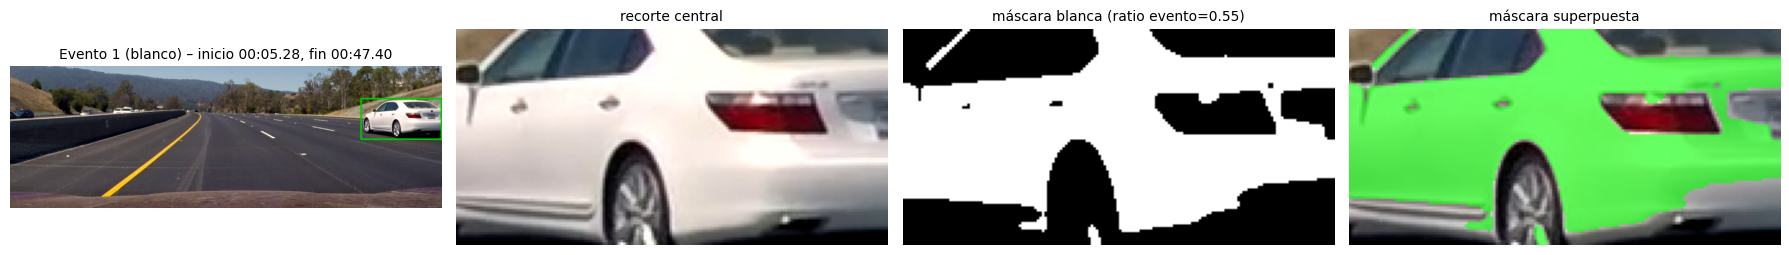

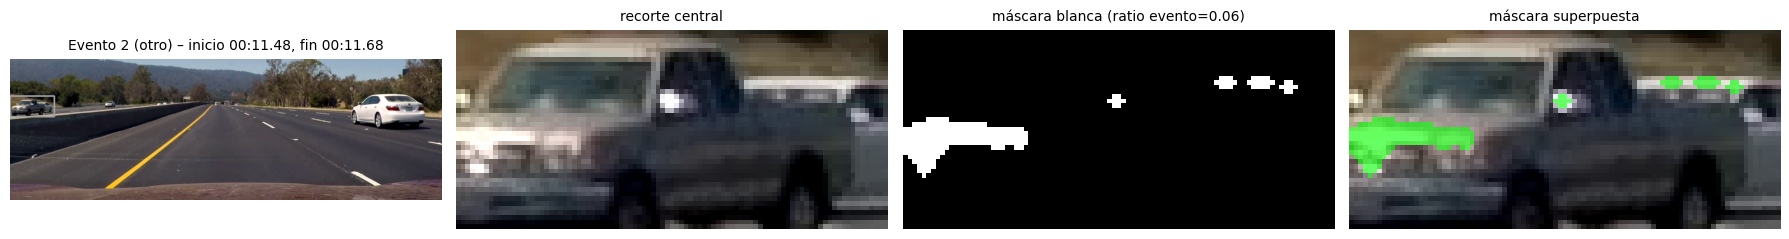

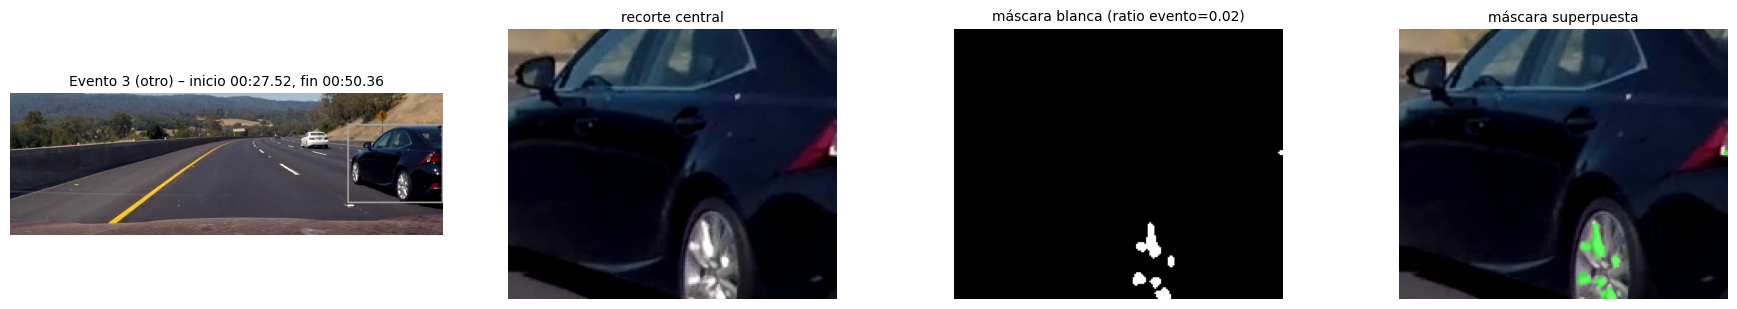

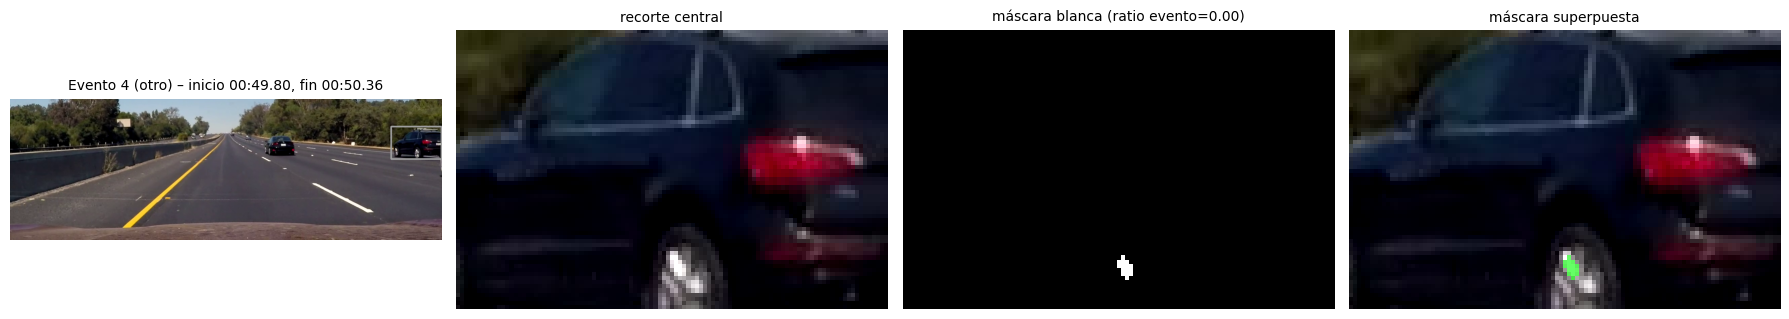

In [15]:
def color_caja(r):
    return (0, 200, 0) if r >= PARAMS["ratio_blanco_min"] else (160, 160, 160)

paneles = []
for e in eventos.itertuples():
    f = leer_frame(e.frame_evidencia)
    x1, y1, x2, y2 = e.caja_evidencia
    cen = recorte_central(f, (x1, y1, x2, y2))
    m = mascara_B(cen)
    over = cen.copy(); over[m > 0] = (0.4 * over[m > 0] + 0.6 * np.array([0, 255, 0])).astype(np.uint8)
    cv2.rectangle(f, (x1, y1), (x2, y2), color_caja(e.ratio_blanco), 3)
    cv2.putText(f, f"evento {e.evento_id} | {e.color} | frame {e.frame_evidencia} | t={seg_a_mmss(e.frame_evidencia/FPS)}",
                (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 255), 2)
    cv2.imwrite(f"{DIR_RES}/evidencias/evento_{e.evento_id:02d}_{e.color}_f{e.frame_evidencia}.jpg", f)
    mostrar([f[300:720], cen, m, over],
            [f"Evento {e.evento_id} ({e.color}) – inicio {e.timestamp_inicio}, fin {e.timestamp_fin}",
             "recorte central", f"máscara blanca (ratio evento={e.ratio_blanco:.2f})", "máscara superpuesta"],
            figsize=(18, 3.2))

In [16]:
# Video anotado completo
det50 = det_todas[det_todas.conf >= PARAMS["conf_umbral"]]
por_frame = {k: g for k, g in det50.groupby("frame")}
activos = lambda nf: eventos[(eventos.frame_inicio <= nf) & (eventos.frame_fin >= nf) & (eventos.color == "blanco")]

cap = cv2.VideoCapture(RUTA_VIDEO)
tmp = f"{DIR_RES}/_video_anotado_tmp.mp4"
out = cv2.VideoWriter(tmp, cv2.VideoWriter_fourcc(*"mp4v"), FPS, (ANCHO, ALTO))
nf = 0
while True:
    ok, f = cap.read()
    if not ok:
        break
    y0, y1 = PARAMS["roi_y"]
    cv2.rectangle(f, (0, y0), (ANCHO - 1, y1), (0, 200, 255), 1)
    for r in (por_frame[nf].itertuples() if nf in por_frame else []):
        c = color_caja(r.ratio_blanco)
        cv2.rectangle(f, (r.x1, r.y1), (r.x2, r.y2), c, 2)
        cv2.putText(f, f"{r.clase} {r.conf:.2f} | blanco {r.ratio_blanco:.2f}", (r.x1, r.y1 - 6),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, c, 2)
    act = activos(nf)
    txt = f"frame {nf}  t={seg_a_mmss(nf / FPS)}  eventos blancos activos: {', '.join(map(str, act.evento_id)) or '-'}"
    cv2.rectangle(f, (0, 0), (ANCHO, 44), (0, 0, 0), -1)
    cv2.putText(f, txt, (12, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2)
    out.write(f); nf += 1
cap.release(); out.release()
# Re-codificación a H.264 (opcional) para que el video se reproduzca en navegadores
salida = f"{DIR_RES}/video_anotado.mp4"
if os.system(f"ffmpeg -y -loglevel error -i {tmp} -c:v libx264 -pix_fmt yuv420p -crf 26 {salida}") == 0:
    os.remove(tmp)
else:
    os.replace(tmp, salida)
print("Video anotado:", salida, f"({os.path.getsize(salida)/1e6:.1f} MB)")

Video anotado: resultados/video_anotado.mp4 (13.5 MB)


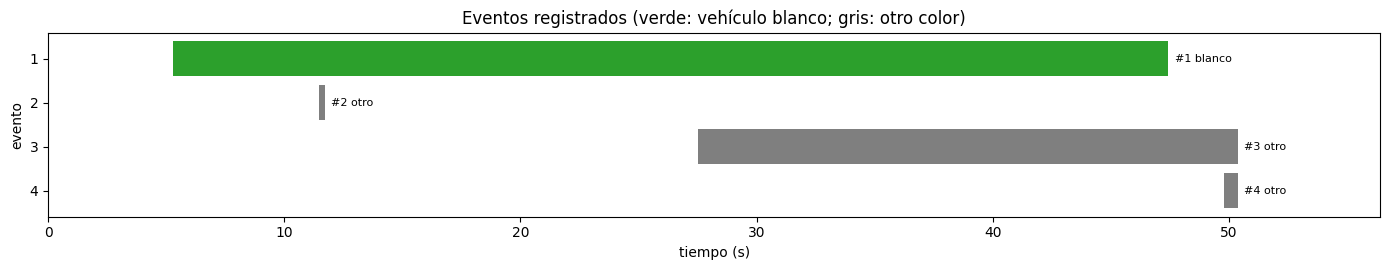

In [17]:
# Línea de tiempo de eventos (lectura rápida del registro)
fig, ax = plt.subplots(figsize=(14, 2.8))
for e in eventos.itertuples():
    c = "tab:green" if e.color == "blanco" else "tab:gray"
    ax.barh(e.evento_id, (e.frame_fin - e.frame_inicio + 1) / FPS, left=e.frame_inicio / FPS, color=c)
    ax.text(e.frame_fin / FPS + 0.3, e.evento_id, f"#{e.evento_id} {e.color}", va="center", fontsize=8)
ax.set_xlabel("tiempo (s)"); ax.set_ylabel("evento"); ax.set_xlim(0, N_FRAMES / FPS + 6); ax.invert_yaxis()
ax.set_title("Eventos registrados (verde: vehículo blanco; gris: otro color)")
plt.tight_layout(); plt.savefig(f"{DIR_RES}/evidencias/linea_de_tiempo.png", dpi=110); plt.show()

## 7. Validación manual, errores y limitaciones

La Actividad 2 del Módulo 2 pide "revisar manualmente una parte del video para comprobar si los eventos tienen sentido" (pág. 45), y el Módulo 2 propone indicadores como *detecciones útiles sobre detecciones totales*, *falsos positivos por secuencia o por minuto* y *estabilidad entre frames* (pág. 39). Se revisó el video completo con una hoja de contacto (un cuadro cada 25 frames, celda siguiente) y los frames de evidencia de cada evento.

**Referencia manual (ground truth) de vehículos cercanos o a media distancia en el carril propio y adyacentes:**

| Vehículo real | Color | Visible (frames) | Observación |
|---|---|---|---|
| V1 | blanco | ~125 → ~1210 | Pasa detrás de V2 entre ~810 y ~870 (oclusión) y sale por el borde derecho al final |
| V2 | negro | ~690 → 1259 | Adelanta por la derecha y queda delante hasta el final |
| V3 | negro | ~1243 → 1259 | Entra por el borde derecho en el último medio segundo |

Además hay vehículos lejanos en los carriles del lado izquierdo del muro, que ocupan pocas decenas de píxeles.

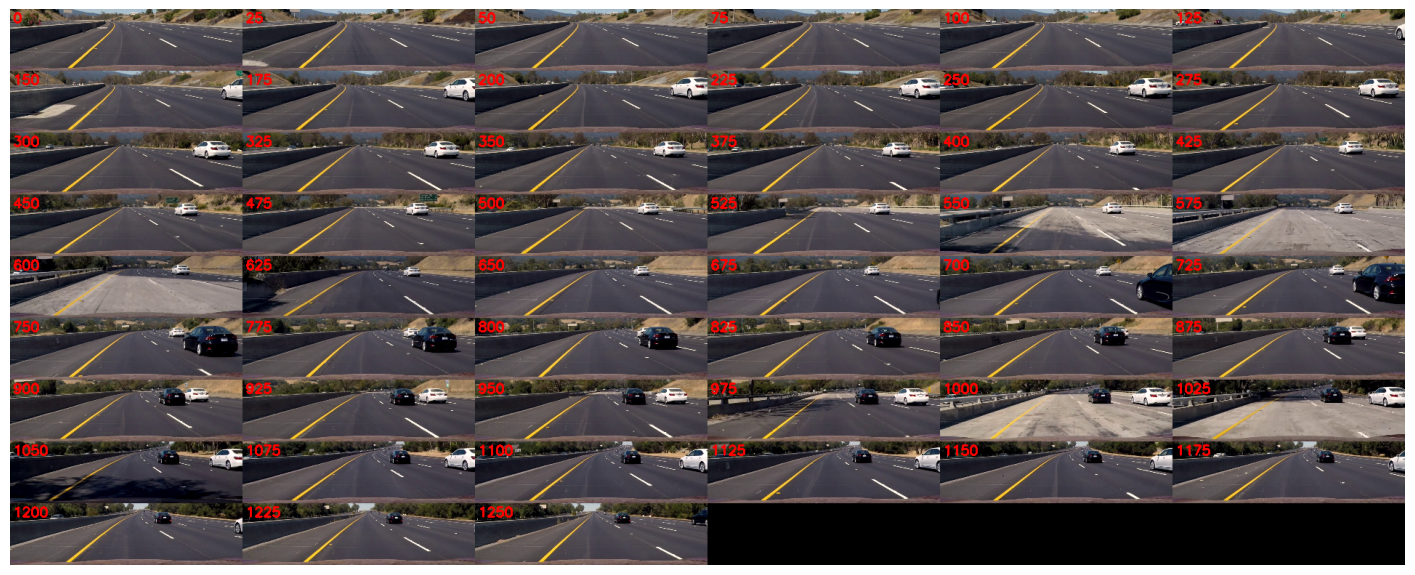

In [18]:
# Hoja de contacto usada para la revisión manual (1 cuadro cada 25 frames, franja de la ROI)
celdas = []
cap = cv2.VideoCapture(RUTA_VIDEO); nf = 0
while True:
    ok, f = cap.read()
    if not ok:
        break
    if nf % 25 == 0:
        s = cv2.resize(f[360:700], (320, 85))
        cv2.putText(s, str(nf), (4, 18), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2); celdas.append(s)
    nf += 1
cap.release()
while len(celdas) % 6: celdas.append(np.zeros_like(celdas[0]))
hoja = np.vstack([np.hstack(celdas[i:i + 6]) for i in range(0, len(celdas), 6)])
cv2.imwrite(f"{DIR_RES}/evidencias/hoja_de_contacto.jpg", hoja)
plt.figure(figsize=(18, 14)); plt.imshow(cv2.cvtColor(hoja, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()

In [19]:
# Revisión manual de cada evento (umbral adoptado): se abrió la imagen de evidencia de cada uno y, si hacía falta,
# los frames de inicio y fin. La anotación es del revisor, no del pipeline; se identifica por frame de inicio.
REVISION_MANUAL = {
    132:  ("V1 (auto blanco)", "blanco", "correcto"),
    287:  ("Pickup y auto plateados en sombra, calzada opuesta, lejanos", "plateado/gris", "correcto (color ambiguo)"),
    688:  ("V2 (auto negro)", "negro", "correcto"),
    1245: ("V3 (auto negro)", "negro", "correcto"),
}
ev_rev = eventos.copy()
ev_rev[["vehiculo_real", "color_real", "resultado"]] = ev_rev.frame_inicio.apply(
    lambda f: pd.Series(REVISION_MANUAL.get(f, ("sin revisar", "?", "sin revisar"))))
display(ev_rev[["evento_id", "color", "frame_inicio", "frame_fin", "timestamp_inicio", "timestamp_fin",
                "duracion_s", "ratio_blanco", "track_ids", "vehiculo_real", "color_real", "resultado"]])
ev_rev.to_csv(f"{DIR_RES}/eventos_revision_manual.csv", index=False)

,evento_id,color,frame_inicio,frame_fin,timestamp_inicio,timestamp_fin,duracion_s,ratio_blanco,track_ids,vehiculo_real,color_real,resultado
0,1,blanco,132,1185,00:05.28,00:47.40,42.16,0.546,1+5+7,V1 (auto blanco),blanco,correcto
1,2,otro,287,292,00:11.48,00:11.68,0.24,0.064,2,"Pickup y auto plateados en sombra, calzada opu...",plateado/gris,correcto (color ambiguo)
2,3,otro,688,1259,00:27.52,00:50.36,22.88,0.017,4,V2 (auto negro),negro,correcto
3,4,otro,1245,1259,00:49.80,00:50.36,0.60,0.003,8,V3 (auto negro),negro,correcto


> **Nota:** la celda anterior deja asentada la asignación manual. Los resultados interpretados, los errores observados y las mejoras propuestas se presentan en el informe que acompaña a este notebook, que se apoya en las tablas y figuras generadas aquí.

In [20]:
# Indicadores de validación (Mód. 2, pág. 39)
d50 = det_todas[det_todas.conf >= PARAMS["conf_umbral"]]
min_video = N_FRAMES / FPS / 60
frames_v1 = set(range(125, 811)) | set(range(870, 1211))     # frames en que V1 es visible y no está tapado
det_blancas = d50[d50.ratio_blanco >= PARAMS["ratio_blanco_min"]]
cobertura_v1 = det_blancas[det_blancas.frame.isin(frames_v1)].frame.nunique() / len(frames_v1)
blancos = ev_rev[ev_rev.color == "blanco"]
fp_color = int(((ev_rev.color == "blanco") & (ev_rev.color_real != "blanco")).sum())
fn_color = int(((ev_rev.color != "blanco") & (ev_rev.color_real == "blanco")).sum())
ind = pd.DataFrame([
    {"indicador": "Vehículos blancos reales en el video (revisión manual)", "valor": 1},
    {"indicador": "Eventos 'blanco' registrados", "valor": len(blancos)},
    {"indicador": "Eventos 'blanco' correctos", "valor": int((blancos.color_real == "blanco").sum())},
    {"indicador": "Falsos positivos de color (evento 'blanco' sobre vehículo no blanco)", "valor": fp_color},
    {"indicador": "Falsos negativos de color (vehículo blanco registrado como 'otro')", "valor": fn_color},
    {"indicador": "Cobertura temporal de V1 (frames visibles con detección 'blanca')", "valor": f"{cobertura_v1:.1%}"},
    {"indicador": "Eventos totales (todos los colores)", "valor": len(ev_rev)},
    {"indicador": "Eventos útiles / eventos totales", "valor": f"{int(ev_rev.resultado.str.startswith('correcto').sum())}/{len(ev_rev)}"},
    {"indicador": "Falsos positivos del detector por minuto de video", "valor": round(int((ev_rev.resultado == 'falso positivo del detector').sum()) / min_video, 2)},
])
ind.to_csv(f"{DIR_RES}/indicadores_validacion.csv", index=False); ind

,indicador,valor
0,Vehículos blancos reales en el video (revisión...,1
1,Eventos 'blanco' registrados,1
2,Eventos 'blanco' correctos,1
3,Falsos positivos de color (evento 'blanco' sob...,0
4,Falsos negativos de color (vehículo blanco reg...,0
5,Cobertura temporal de V1 (frames visibles con ...,88.9%
6,Eventos totales (todos los colores),4
7,Eventos útiles / eventos totales,4/4
8,Falsos positivos del detector por minuto de video,0.0


## 8. Referencias al material de la materia

* Universidad Blas Pascal. *Visión por Computadora – material didáctico*, Lic. en Inteligencia Artificial:
  * Módulo 1: tareas de visión (pág. 14); imagen digital, `uint8` y normalización (págs. 15–16); preprocesamiento, filtros, umbralización (pág. 17); espacios de color y BGR en OpenCV (pág. 18); de imagen a pipeline y reproducibilidad (pág. 19); glosario (págs. 21–22); Actividades 1 a 5 (págs. 23–32), en particular **Actividad 4: Mini pipeline integrador** (págs. 29–30).
  * Módulo 2: del caso de uso al requerimiento técnico (pág. 35); detección con modelos preentrenados, confianza, umbral y NMS; video, FPS, persistencia y eventos (pág. 36); segmentación (pág. 37); calidad de resultados y validación inicial (pág. 39); ética (pág. 40); glosario (págs. 42–43); Actividad 1 (págs. 43–45), **Actividad 2: Detección en video con registro de eventos** (págs. 45–47) y Actividad 3 (págs. 47–49).
* OpenCV-Python tutorials (bibliografía complementaria de la materia, pág. 8).
* Material visual: `project_video.mp4`, repositorio *udacity/CarND-Vehicle-Detection* (licencia MIT).
* Modelo: MobileNet-SSD (Caffe) entrenado sobre PASCAL VOC, repositorio *chuanqi305/MobileNet-SSD* (licencia MIT).